# First making 7 day trend figure

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import warnings
warnings.filterwarnings('ignore')

In [2]:
file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_filtered_merged_32cols_pps_smap_no2_soil_state_localtime.parquet'
df = pd.read_parquet(file, engine='pyarrow')


# detecting dry pulses

In [3]:
def detect_pulses(
    df,
    dry_days=7,
    dry_sum_thresh_mm=2.5,
    rain_hourly_thresh=2.5
):
    """
    Detect precipitation pulse events following a dry spell.

    Parameters
    ----------
    dry_days : int
        Number of days in the lookback window for dryness check.
    dry_sum_thresh_mm : float
        Max cumulative precip (mm) in the dry window to qualify as dry.
    rain_hourly_thresh : float
        Min hourly precip (mm/hr) to trigger a pulse.

    Returns
    -------
    DataFrame with boolean column 'pulse_start'.
    """
    d = df.copy()
    d['datetime'] = pd.to_datetime(d['datetime'])
    d = d.sort_values(['grid_lat', 'grid_lon', 'datetime'])
    d['h_precip_mm'] = pd.to_numeric(d['h_precip_mm'], errors='coerce').fillna(0)

    dry_hours = int(dry_days * 24)
    out = []

    for (lat, lon), g in d.groupby(['grid_lat', 'grid_lon'], sort=False):
        g = g.set_index('datetime').sort_index()

        roll_sum = g['h_precip_mm'].rolling(dry_hours, min_periods=dry_hours).sum()
        g['dry_window'] = (roll_sum < dry_sum_thresh_mm).astype('boolean')
        prev_dry = g['dry_window'].shift(1, fill_value=False)

        g['pulse_start'] = ((g['h_precip_mm'] > rain_hourly_thresh) & prev_dry).astype('boolean')
        out.append(g.reset_index())

    return pd.concat(out, ignore_index=True)

In [4]:
pulses = detect_pulses(df,dry_days=7,dry_sum_thresh_mm=2.5,rain_hourly_thresh=5)

n_pulses = int(pulses['pulse_start'].sum())
print(f"Total pulses detected: {n_pulses:,}")

Total pulses detected: 459


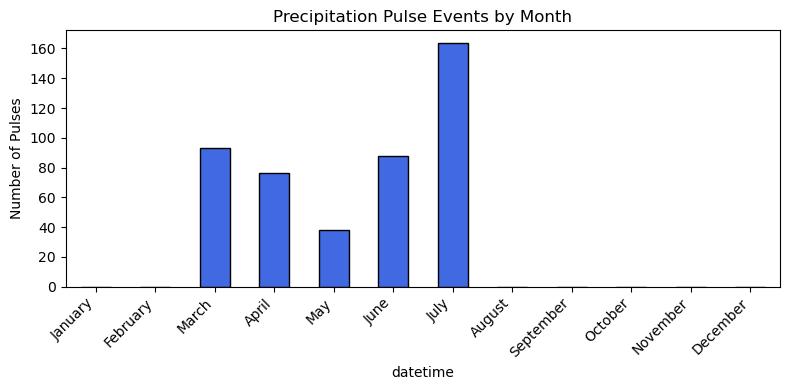

In [5]:
#inspect pulses by month 
pulse_times = pulses.loc[pulses['pulse_start'], 'datetime']
month_counts = pulse_times.dt.month_name().value_counts().reindex(
    ['January','February','March','April','May','June',
     'July','August','September','October','November','December']
)
plt.figure(figsize=(8, 4))
month_counts.plot(kind='bar', color='royalblue', edgecolor='black')
plt.ylabel('Number of Pulses')
plt.title('Precipitation Pulse Events by Month')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [6]:
def build_event_windows(df, window_days=3):
    """
    For each pulse_start, extract a ± window_days slice and tag lag_hours.
    """
    df = df.sort_values(['grid_lat', 'grid_lon', 'datetime']).copy()
    df['datetime'] = pd.to_datetime(df['datetime'])

    window = pd.Timedelta(days=window_days)
    events = []
    event_id = 0

    for (lat, lon), g in df.groupby(['grid_lat', 'grid_lon'], sort=False):
        g = g.set_index('datetime').sort_index()
        pulse_times = g.index[g['pulse_start'].fillna(False)]

        for t in pulse_times:
            sub = g.loc[t - window : t + window].copy()
            if sub.empty:
                continue
            sub['event_id'] = event_id
            sub['event_time'] = t
            sub['lag_hours'] = ((sub.index - t).total_seconds() // 3600).astype(int)
            sub['grid_lat'] = lat
            sub['grid_lon'] = lon
            events.append(sub.reset_index())
            event_id += 1

    return pd.concat(events, ignore_index=True) if events else pd.DataFrame()

In [7]:
events = build_event_windows(pulses, window_days=7)
print(f"Event windows built: {events['event_id'].nunique():,} events, {len(events):,} rows")

Event windows built: 459 events, 150,374 rows


# add no2 rolling background mean

In [8]:
def add_no2_rolling_background(df, no2_col='no2_mean', bg_days=7, min_obs=12):
    """
    Compute a trailing bg_days rolling mean of NO₂ for each grid cell.
    Uses .shift(1) so the background at time t excludes t itself.
    Requires at least min_obs valid observations in the window.
    """
    d = df.copy()
    d['datetime'] = pd.to_datetime(d['datetime'])
    d = d.sort_values(['grid_lat', 'grid_lon', 'datetime'])

    out = []
    for (lat, lon), g in d.groupby(['grid_lat', 'grid_lon'], sort=False):
        g = g.set_index('datetime').sort_index()
        s = g[no2_col]

        bg_mean = s.rolling(f'{bg_days}D').mean().shift(1)
        bg_cnt  = s.rolling(f'{bg_days}D').count().shift(1)
        bg_mean = bg_mean.where(bg_cnt >= min_obs)

        g[f'{no2_col}_bg'] = bg_mean
        out.append(g.reset_index())

    return pd.concat(out, ignore_index=True)

In [9]:
events_bg = add_no2_rolling_background(events, no2_col='no2_mean', bg_days=7, min_obs=12)
print(f"Background coverage: {events_bg['no2_mean_bg'].notna().mean():.1%} of rows have a valid bg")

Background coverage: 34.7% of rows have a valid bg


# normalize no2 

In [10]:
def normalize_no2_to_ratio(events, no2_col='no2_mean'):
    """
    For each event, divide NO₂ by the background value at lag=0.
    Produces 'no2_norm' as a ratio (1.0 = background level).
    Events with missing background at lag=0 are dropped.
    """
    e = events.copy()
    if e.empty:
        return e

    bg_col = f'{no2_col}_bg'

    def _norm(g):
        bg0_rows = g.loc[g['lag_hours'] == 0, bg_col]
        bg0 = bg0_rows.iloc[0] if len(bg0_rows) else np.nan
        g['no2_bg0'] = bg0
        if pd.notna(bg0) and bg0 != 0:
            g['no2_norm'] = g[no2_col] / bg0
        else:
            g['no2_norm'] = np.nan
        return g

    e = e.groupby('event_id', group_keys=False).apply(_norm)

    # Drop events without a valid background
    valid_ids = e.loc[(e['lag_hours'] == 0) & (e['no2_bg0'].notna()), 'event_id'].unique()
    e = e[e['event_id'].isin(valid_ids)]
    print(f"Events retained after normalization: {e['event_id'].nunique():,}")
    return e

In [11]:
events_norm = normalize_no2_to_ratio(events_bg)

Events retained after normalization: 228


# build composites -- mean and SD

In [12]:
def build_composite(events, vars_to_comp=('no2_norm', 'WFPS_c', 'h_precip_mm','surface_temp','soil_temp_layer1')):
    """
    Aggregate mean, std, and count at each lag_hours across all events.
    Returns a flat DataFrame with columns <var>_mean, <var>_std, <var>_count.
    """
    if events.empty:
        return pd.DataFrame()

    comp = (events.groupby('lag_hours')[list(vars_to_comp)]
                  .agg(['mean', 'std', 'count'])
                  .sort_index())
    comp.columns = ['_'.join(c) for c in comp.columns]
    return comp.reset_index()

In [13]:
comp_raw = build_composite(
    events_norm,
    vars_to_comp=('no2_norm', 'WFPS_c', 'h_precip_mm','surface_temp','soil_temp_layer1')
)
print(f"Composite has {len(comp_raw)} lag-hour rows")
comp_raw.head()

Composite has 337 lag-hour rows


,lag_hours,no2_norm_mean,no2_norm_std,no2_norm_count,WFPS_c_mean,WFPS_c_std,WFPS_c_count,h_precip_mm_mean,h_precip_mm_std,h_precip_mm_count,surface_temp_mean,surface_temp_std,surface_temp_count,soil_temp_layer1_mean,soil_temp_layer1_std,soil_temp_layer1_count
0,-168,1.076906,0.379264,38,0.607157,0.136098,228,0.008443,0.063335,228,292.801666,7.543347,228,291.686768,5.643435,228
1,-167,1.048878,0.347662,34,0.607120,0.135897,228,0.003114,0.022369,228,292.663544,7.744279,228,291.727295,5.825704,228
2,-166,1.040036,0.329949,31,0.606190,0.137178,229,0.000175,0.001805,229,292.448853,7.826921,229,291.745941,5.983210,229
3,-165,0.953276,0.312247,26,0.605318,0.138528,230,0.000761,0.006522,230,292.213898,7.743620,230,291.726959,6.100093,230
4,-164,1.094817,0.308467,21,0.607685,0.138413,228,0.007105,0.050092,228,291.876923,7.499007,228,291.611786,6.186028,228


# building confidence intervals around events

In [14]:
def build_ci_cols(df, mean_col, std_col, n_col, out_prefix, z=1.96):
    """Compute mean ± z*SEM and return as *_mean_s, *_lo_s, *_hi_s columns."""
    n   = df[n_col].clip(lower=1).astype(float)
    sem = df[std_col].astype(float) / np.sqrt(n)
    m   = df[mean_col].astype(float)
    return pd.DataFrame({
        f'{out_prefix}_mean_s': m,
        f'{out_prefix}_lo_s':   m - z * sem,
        f'{out_prefix}_hi_s':   m + z * sem,
    })

In [15]:
comp = comp_raw[['lag_hours']].copy()

comp = comp.join(build_ci_cols(comp_raw,
    mean_col='h_precip_mm_mean', std_col='h_precip_mm_std', n_col='h_precip_mm_count',
    out_prefix='h_precip_mm'))

comp = comp.join(build_ci_cols(comp_raw,
    mean_col='WFPS_c_mean', std_col='WFPS_c_std', n_col='WFPS_c_count',
    out_prefix='WFPS_c'))

comp = comp.join(build_ci_cols(comp_raw,
    mean_col='no2_norm_mean', std_col='no2_norm_std', n_col='no2_norm_count',
    out_prefix='no2_norm'))

comp = comp.join(build_ci_cols(comp_raw,
    mean_col='surface_temp_mean', std_col='surface_temp_std', n_col='surface_temp_count',
    out_prefix='surface_temp_norm'))

comp = comp.join(build_ci_cols(comp_raw,
    mean_col='soil_temp_layer1_mean', std_col='soil_temp_layer1_std', n_col='soil_temp_layer1_count',
    out_prefix='soil_temp_layer1_norm'))

x = comp['lag_hours'].to_numpy()
print("comp columns:", comp.columns.tolist())
comp.head()

comp columns: ['lag_hours', 'h_precip_mm_mean_s', 'h_precip_mm_lo_s', 'h_precip_mm_hi_s', 'WFPS_c_mean_s', 'WFPS_c_lo_s', 'WFPS_c_hi_s', 'no2_norm_mean_s', 'no2_norm_lo_s', 'no2_norm_hi_s', 'surface_temp_norm_mean_s', 'surface_temp_norm_lo_s', 'surface_temp_norm_hi_s', 'soil_temp_layer1_norm_mean_s', 'soil_temp_layer1_norm_lo_s', 'soil_temp_layer1_norm_hi_s']


,lag_hours,h_precip_mm_mean_s,h_precip_mm_lo_s,h_precip_mm_hi_s,WFPS_c_mean_s,WFPS_c_lo_s,WFPS_c_hi_s,no2_norm_mean_s,no2_norm_lo_s,no2_norm_hi_s,surface_temp_norm_mean_s,surface_temp_norm_lo_s,surface_temp_norm_hi_s,soil_temp_layer1_norm_mean_s,soil_temp_layer1_norm_lo_s,soil_temp_layer1_norm_hi_s
0,-168,0.008443,0.000222,0.016664,0.607157,0.589491,0.624823,1.076906,0.956318,1.197495,292.801666,291.822508,293.780824,291.686768,290.954226,292.419309
1,-167,0.003114,0.000210,0.006018,0.607120,0.589480,0.624760,1.048878,0.932016,1.165741,292.663544,291.658304,293.668783,291.727295,290.971094,292.483496
2,-166,0.000175,-0.000059,0.000408,0.606190,0.588423,0.623957,1.040036,0.923886,1.156187,292.448853,291.435106,293.462599,291.745941,290.970993,292.520889
3,-165,0.000761,-0.000082,0.001604,0.605318,0.587415,0.623221,0.953276,0.833252,1.073300,292.213898,291.213123,293.214672,291.726959,290.938592,292.515327
4,-164,0.007105,0.000603,0.013607,0.607685,0.589719,0.625652,1.094817,0.962883,1.226750,291.876923,290.903520,292.850325,291.611786,290.808814,292.414758


Saved: wfps_no2_figure.png


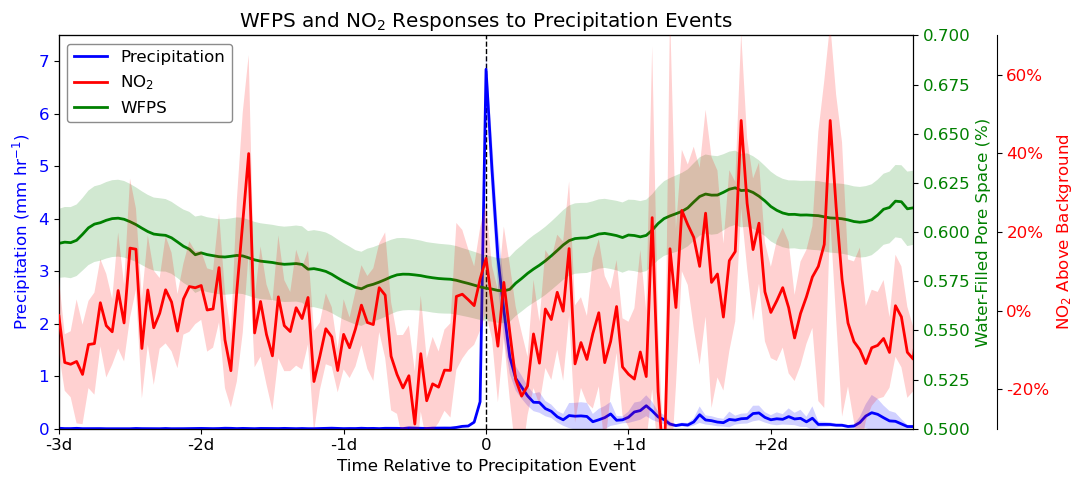

In [16]:
#set figure style 
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['font.size']       = 12
plt.rcParams['axes.labelsize']  = 12
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 12

fig, ax_precip = plt.subplots(figsize=(11, 5))

#precip-- left axis, blue 
ax_precip.plot(x, comp['h_precip_mm_mean_s'], lw=2.0, color='blue',
               label='Precipitation (IMERG-GPM)', zorder=5)
ax_precip.fill_between(x, comp['h_precip_mm_lo_s'], comp['h_precip_mm_hi_s'],
                        color='blue', alpha=0.18, edgecolor='none', zorder=4)
ax_precip.set_ylabel('Precipitation (mm hr$^{-1}$)', color='blue')
ax_precip.tick_params(axis='y', labelcolor='blue')
ax_precip.set_ylim(bottom=0)

#WFPS-- right axis, green
ax_wfps = ax_precip.twinx()
ax_wfps.plot(x, comp['WFPS_c_mean_s'], lw=2.0, color='green',
             label='WFPS (SMAP)', zorder=2)
ax_wfps.fill_between(x, comp['WFPS_c_lo_s'], comp['WFPS_c_hi_s'],
                     color='green', alpha=0.18, edgecolor='none', zorder=1)
ax_wfps.set_ylabel('Water-Filled Pore Space (%)', color='green')
ax_wfps.tick_params(axis='y', labelcolor='green')
ax_wfps.set_ylim(0.5,0.7)

#NO2 axis-- offset far-right axis, red
ax_no2 = ax_precip.twinx()
ax_no2.spines['right'].set_position(('outward', 60))
ax_no2.plot(x, comp['no2_norm_mean_s'], lw=2.0, color='red',
            label='NO$_2$ (TEMPO)', zorder=8)
ax_no2.fill_between(x, comp['no2_norm_lo_s'], comp['no2_norm_hi_s'], color='red', alpha=0.18, edgecolor='none', zorder=7)
ax_no2.set_ylabel('NO$_2$ Above Background', color='red')
ax_no2.tick_params(axis='y', labelcolor='red')
ax_no2.yaxis.set_major_formatter(FuncFormatter(lambda v, pos: f'{(v-1)*100:.0f}%')) #formatted as % deviation from background (1.05 --> +5%
ax_no2.set_ylim(0.7, 1.7)

#labels and axes 
ax_precip.axvline(0, ls='--', c='k', lw=1)
ax_precip.set_xlabel('Time Relative to Precipitation Event')
ax_precip.set_xlim(-72, 72)
ax_precip.set_xticks(range(-72, 71, 24))
ax_precip.set_xticklabels([f'{h//24:+d}d' if h != 0 else '0' for h in range(-72, 72, 24)])
ax_precip.set_title(
    'WFPS and NO$_2$ Responses to Precipitation Events')

#combined legend
handles = [
    ax_precip.lines[0],
    ax_no2.lines[0],
    ax_wfps.lines[0],
]
labels = [
    'Precipitation',
    'NO$_2$',
    'WFPS',
]
ax_precip.legend(handles, labels, loc='upper left',
                 frameon=True, facecolor='white', edgecolor='gray',
                 framealpha=0.9, fontsize=12)

plt.tight_layout()

plt.savefig('wfps_no2_figure.png', dpi=300, bbox_inches='tight')
print('Saved: wfps_no2_figure.png')

plt.show()

Saved: low_CF_scaled_wfps_no2_figure.png


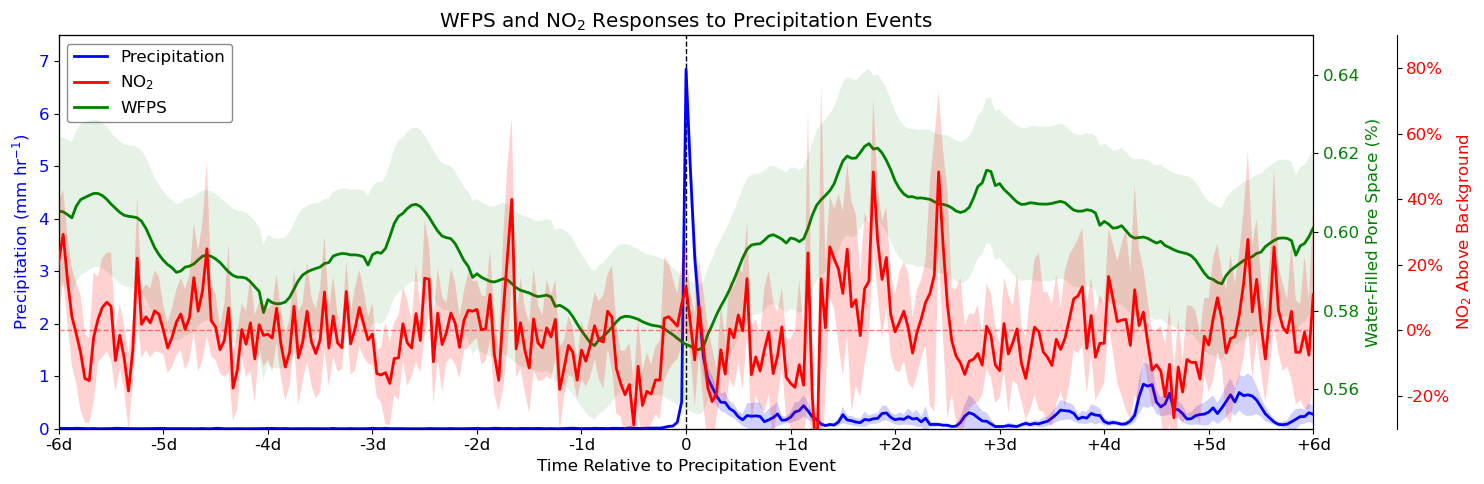

In [17]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# -----------------------------
# Figure style
# -----------------------------
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['xtick.labelsize'] = 12
plt.rcParams['ytick.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 12

fig, ax_precip = plt.subplots(figsize=(15, 5))

# -----------------------------
# Precipitation axis — left, blue
# -----------------------------
p_line, = ax_precip.plot(
    x,
    comp['h_precip_mm_mean_s'],
    lw=2.0,
    color='blue',
    label='Precipitation (IMERG-GPM)',
    zorder=5
)

ax_precip.fill_between(
    x,
    comp['h_precip_mm_lo_s'],
    comp['h_precip_mm_hi_s'],
    color='blue',
    alpha=0.18,
    edgecolor='none',
    zorder=4
)

ax_precip.set_ylabel('Precipitation (mm hr$^{-1}$)', color='blue')
ax_precip.tick_params(axis='y', labelcolor='blue')
ax_precip.set_ylim(bottom=0)

# -----------------------------
# WFPS axis — right, green
# -----------------------------
ax_wfps = ax_precip.twinx()

w_line, = ax_wfps.plot(
    x,
    comp['WFPS_c_mean_s'],
    lw=2.0,
    color='green',
    label='WFPS (SMAP)',
    zorder=2
)

ax_wfps.fill_between(
    x,
    comp['WFPS_c_lo_s'],
    comp['WFPS_c_hi_s'],
    color='green',
    alpha=0.10,
    edgecolor='none',
    zorder=1
)

ax_wfps.set_ylabel('Water-Filled Pore Space (%)', color='green')
ax_wfps.tick_params(axis='y', labelcolor='green')
ax_wfps.set_ylim(0.55, 0.65)

# -----------------------------
# NO2 axis — offset far-right, red
# -----------------------------
ax_no2 = ax_precip.twinx()
ax_no2.spines['right'].set_position(('outward', 60))

n_line, = ax_no2.plot(
    x,
    comp['no2_norm_mean_s'],
    lw=2.0,
    color='red',
    label='NO$_2$ (TEMPO)',
    zorder=8
)

ax_no2.fill_between(
    x,
    comp['no2_norm_lo_s'],
    comp['no2_norm_hi_s'],
    color='red',
    alpha=0.18,
    edgecolor='none',
    zorder=7
)

# reference line at background = 1.0
ax_no2.axhline(
    1.0,
    ls='--',
    color='red',
    lw=1,
    alpha=0.5,
    zorder=6
)

ax_no2.set_ylabel('NO$_2$ Above Background', color='red')
ax_no2.tick_params(axis='y', labelcolor='red')

# format normalized NO2 as percent above/below background
ax_no2.yaxis.set_major_formatter(
    FuncFormatter(lambda v, pos: f'{(v - 1) * 100:.0f}%')
)

ax_no2.set_ylim(0.7, 1.9)

# -----------------------------
# Shared x-axis labels and event marker
# -----------------------------
ax_precip.axvline(0, ls='--', color='k', lw=1)

ax_precip.set_xlabel('Time Relative to Precipitation Event')
ax_precip.set_xlim(-144, 144)
ax_precip.set_xticks(range(-144, 145, 24))
ax_precip.set_xticklabels(
    [f'{h // 24:+d}d' if h != 0 else '0' for h in range(-144, 145, 24)]
)

ax_precip.set_title('WFPS and NO$_2$ Responses to Precipitation Events')

# -----------------------------
# Combined legend
# -----------------------------
ax_precip.legend(
    handles=[p_line, n_line, w_line],
    labels=['Precipitation', 'NO$_2$', 'WFPS'],
    loc='upper left',
    frameon=True,
    facecolor='white',
    edgecolor='gray',
    framealpha=0.9,
    fontsize=12
)

# -----------------------------
# Final layout and save
# -----------------------------
plt.tight_layout()

plt.savefig(
    'wfps_no2_figure.png',
    dpi=300,
    bbox_inches='tight'
)

print('Saved: low_CF_scaled_wfps_no2_figure.png')

plt.show()

Saved: low_CF_scaled_wfps_no2_figure.png


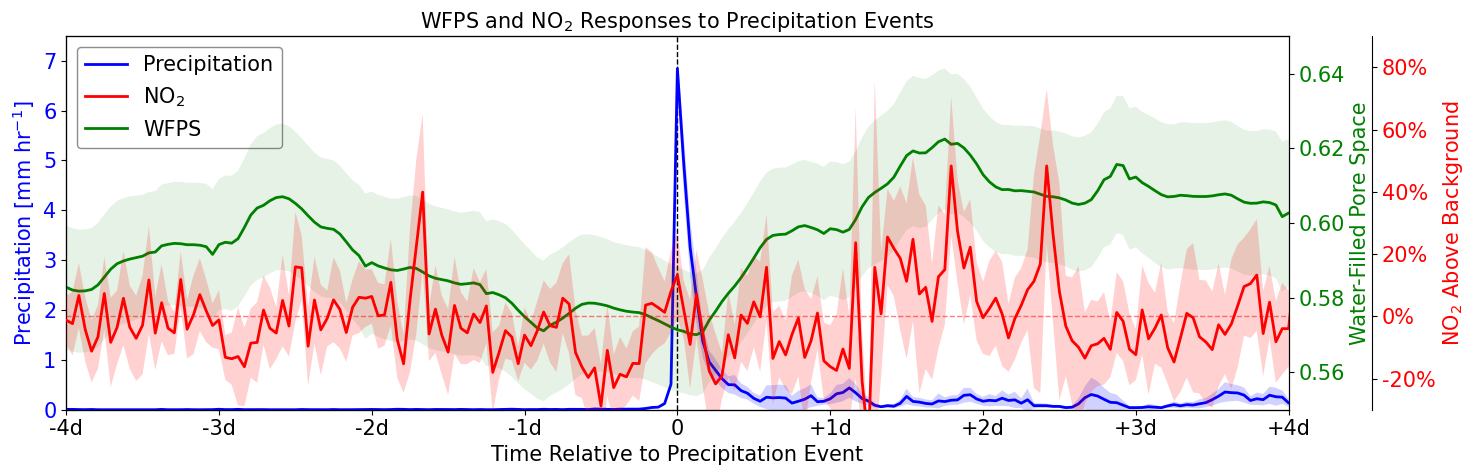

In [18]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# -----------------------------
# Figure style
# -----------------------------
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15

fig, ax_precip = plt.subplots(figsize=(15, 5))

# -----------------------------
# Precipitation axis — left, blue
# -----------------------------
p_line, = ax_precip.plot(
    x,
    comp['h_precip_mm_mean_s'],
    lw=2.0,
    color='blue',
    label='Precipitation (IMERG-GPM)',
    zorder=5
)

ax_precip.fill_between(
    x,
    comp['h_precip_mm_lo_s'],
    comp['h_precip_mm_hi_s'],
    color='blue',
    alpha=0.18,
    edgecolor='none',
    zorder=4
)

ax_precip.set_ylabel('Precipitation [mm hr$^{-1}$]', color='blue')
ax_precip.tick_params(axis='y', labelcolor='blue')
ax_precip.set_ylim(bottom=0)

# -----------------------------
# WFPS axis — right, green
# -----------------------------
ax_wfps = ax_precip.twinx()

w_line, = ax_wfps.plot(
    x,
    comp['WFPS_c_mean_s'],
    lw=2.0,
    color='green',
    label='WFPS (SMAP)',
    zorder=2
)

ax_wfps.fill_between(
    x,
    comp['WFPS_c_lo_s'],
    comp['WFPS_c_hi_s'],
    color='green',
    alpha=0.10,
    edgecolor='none',
    zorder=1
)

ax_wfps.set_ylabel('Water-Filled Pore Space', color='green')
ax_wfps.tick_params(axis='y', labelcolor='green')
ax_wfps.set_ylim(0.55, 0.65)

# -----------------------------
# NO2 axis — offset far-right, red
# -----------------------------
ax_no2 = ax_precip.twinx()
ax_no2.spines['right'].set_position(('outward', 60))

n_line, = ax_no2.plot(
    x,
    comp['no2_norm_mean_s'],
    lw=2.0,
    color='red',
    label='NO$_2$ (TEMPO)',
    zorder=8
)

ax_no2.fill_between(
    x,
    comp['no2_norm_lo_s'],
    comp['no2_norm_hi_s'],
    color='red',
    alpha=0.18,
    edgecolor='none',
    zorder=7
)

# reference line at background = 1.0
ax_no2.axhline(
    1.0,
    ls='--',
    color='red',
    lw=1,
    alpha=0.5,
    zorder=6
)

ax_no2.set_ylabel('NO$_2$ Above Background', color='red')
ax_no2.tick_params(axis='y', labelcolor='red')

# format normalized NO2 as percent above/below background
ax_no2.yaxis.set_major_formatter(
    FuncFormatter(lambda v, pos: f'{(v - 1) * 100:.0f}%')
)

ax_no2.set_ylim(0.7, 1.9)

# -----------------------------
# Shared x-axis labels and event marker
# -----------------------------
ax_precip.axvline(0, ls='--', color='k', lw=1)

ax_precip.set_xlabel('Time Relative to Precipitation Event')
ax_precip.set_xlim(-96, 96)
ax_precip.set_xticks(range(-96, 97, 24))
ax_precip.set_xticklabels(
    [f'{h // 24:+d}d' if h != 0 else '0' for h in range(-96, 97, 24)]
)

ax_precip.set_title('WFPS and NO$_2$ Responses to Precipitation Events', fontsize=15)

# -----------------------------
# Combined legend
# -----------------------------
ax_precip.legend(
    handles=[p_line, n_line, w_line],
    labels=['Precipitation', 'NO$_2$', 'WFPS'],
    loc='upper left',
    frameon=True,
    facecolor='white',
    edgecolor='gray',
    framealpha=0.9,
    fontsize=15
)

# -----------------------------
# Final layout and save
# -----------------------------
plt.tight_layout()

plt.savefig(
    '/global/home/users/toireasamarie/Paper_Workflow/Paper Figures/precip_dry_periods_fig.png', 
    dpi=300, bbox_inches='tight')

print('Saved: low_CF_scaled_wfps_no2_figure.png')

plt.show()

In [19]:
df

,grid_lat,grid_lon,h_precip_mm,datetime,no2_mean,no2_std,no2_sem,snow_ice_fraction_mean,snow_ice_fraction_std,cv_no2,...,pct_loamy_sand,pct_sand,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name
0,36.05,-91.15,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas
1,36.05,-91.05,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,47.916667,0.0,33.333333,0.000000,2.083333,Arkansas
2,36.05,-90.95,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,1.515152,0.0,46.212121,22.727273,26.515152,Arkansas
3,36.05,-90.85,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,8.333333,0.0,65.972222,2.777778,11.805556,Arkansas
4,36.05,-90.75,NaN,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,1.515152,0.0,76.515152,0.000000,4.545455,Arkansas
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33395116,48.95,-97.25,0.230,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.000000,0.0,0.000000,77.272727,22.727273,North Dakota
33395117,48.95,-97.15,0.115,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.000000,0.0,0.000000,36.111111,59.027778,Minnesota
33395118,48.95,-97.05,0.075,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,0.000000,0.0,0.000000,12.878788,0.757576,Minnesota
33395119,48.95,-96.95,0.025,2024-07-31 23:00:00,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00000,0.0,0.0,0.000000,25.000000,0.0,0.000000,0.000000,0.000000,Minnesota


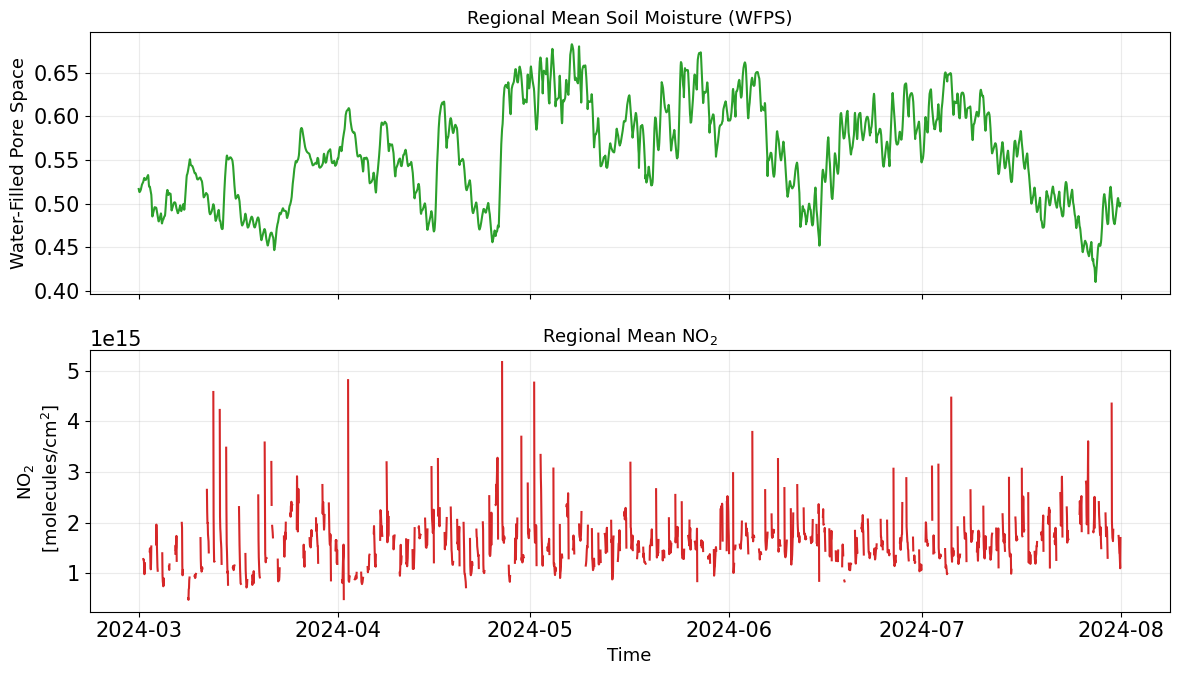

In [20]:
df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

#aggregate over region 
regional = (
    df_plot.groupby("datetime")
    .agg(
        WFPS=("WFPS_c", "mean"),
        NO2=("no2_mean", "mean"),
        precip=("h_precip_mm", "mean")
    )
    .reset_index()
)

# create subplots 
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True
)

# #precipitation
# axes[0].plot(
#     regional["datetime"],
#     regional["precip"],
#     color="tab:blue"
# )
# axes[0].set_ylabel("Precip (mm/hr)", color="tab:blue")
# axes[0].set_title("Regional Mean Precipitation")
# axes[0].grid(alpha=0.25)

#Soil moisture (WFPS)
axes[0].plot(
    regional["datetime"],
    regional["WFPS"],
    color="tab:green"
)
axes[0].set_ylabel("Water-Filled Pore Space", fontsize = 13)
axes[0].set_title("Regional Mean Soil Moisture (WFPS)",fontsize=13)
axes[0].grid(alpha=0.25)

#NO2
axes[1].plot(
    regional["datetime"],
    regional["NO2"],
    color="tab:red"
)
axes[1].set_ylabel("NO$_2$ \n [molecules/cm$^2$]", fontsize=13)
axes[1].set_title("Regional Mean NO$_2$",fontsize=13)
axes[1].grid(alpha=0.25)

# shared x-axis
axes[1].set_xlabel("Time", fontsize=13)

plt.tight_layout()
#plt.savefig('global/home/users/toireasamarie/Paper_Workflow/Paper Figures/
plt.show()

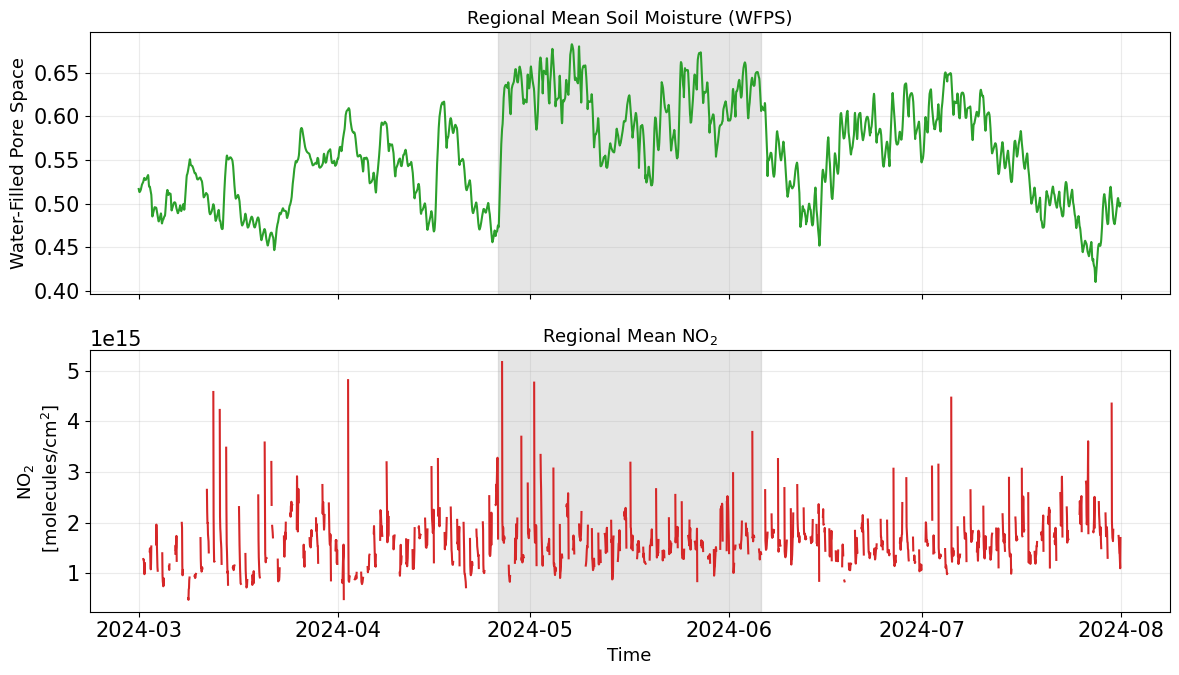

In [21]:
df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

# aggregate over region 
regional = (
    df_plot.groupby("datetime")
    .agg(
        WFPS=("WFPS_c", "mean"),
        NO2=("no2_mean", "mean"),
        precip=("h_precip_mm", "mean")
    )
    .reset_index()
)

# highlighted region dates
start_date = pd.to_datetime("2024-04-26")
end_date = pd.to_datetime("2024-06-06")

# create subplots 
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7),
    sharex=True
)

# Soil moisture (WFPS)
axes[0].plot(
    regional["datetime"],
    regional["WFPS"],
    color="tab:green"
)
axes[0].set_ylabel("Water-Filled Pore Space", fontsize=13)
axes[0].set_title("Regional Mean Soil Moisture (WFPS)", fontsize=13)
axes[0].grid(alpha=0.25)

# NO2
axes[1].plot(
    regional["datetime"],
    regional["NO2"],
    color="tab:red"
)
axes[1].set_ylabel("NO$_2$ \n [molecules/cm$^2$]", fontsize=13)
axes[1].set_title("Regional Mean NO$_2$", fontsize=13)
axes[1].grid(alpha=0.25)

# Highlight region in both panels
for ax in axes:
    ax.axvspan(
        start_date,
        end_date,
        color="gray",
        alpha=0.2
    )
# shared x-axis
axes[1].set_xlabel("Time", fontsize=13)

plt.tight_layout()
plt.savefig('/global/home/users/toireasamarie/Paper_Workflow/Paper Figures/regional_mean_plot.png', dpi=300)
plt.show()

# combining both figures together

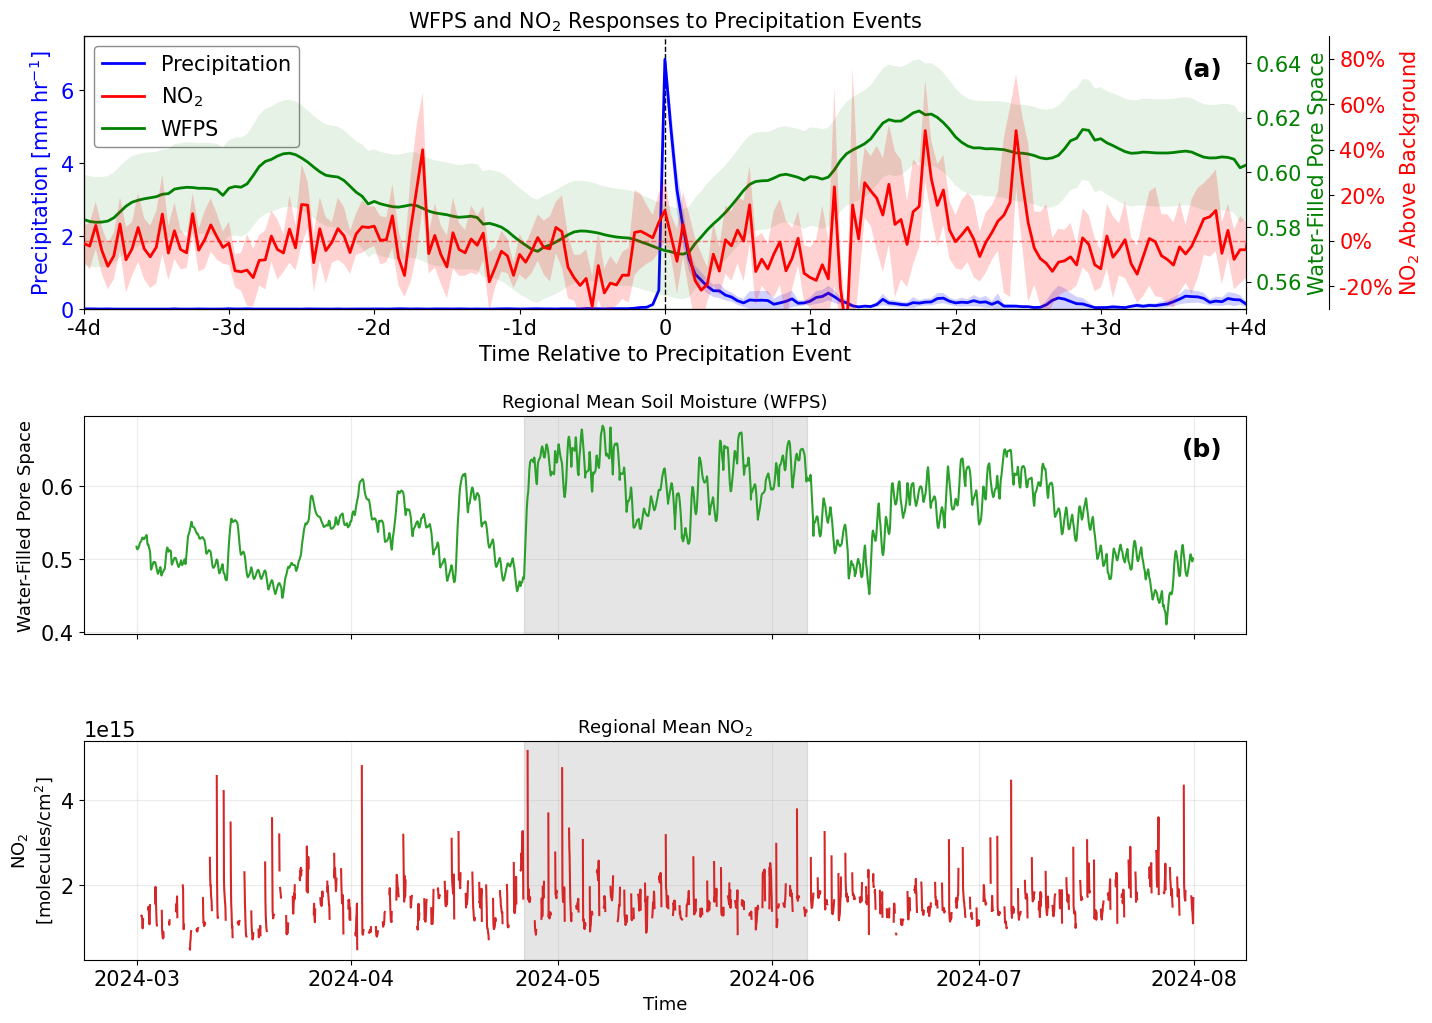

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.gridspec as gridspec

# -----------------------------
# Figure style
# -----------------------------
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15

# -----------------------------
# Regional mean data
# -----------------------------
df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

regional = (
    df_plot.groupby("datetime")
    .agg(
        WFPS=("WFPS_c", "mean"),
        NO2=("no2_mean", "mean"),
        precip=("h_precip_mm", "mean")
    )
    .reset_index()
)

# highlighted region dates
start_date = pd.to_datetime("2024-04-26")
end_date = pd.to_datetime("2024-06-06")

# -----------------------------
# Combined figure layout
# -----------------------------
fig = plt.figure(figsize=(15, 12))

gs = gridspec.GridSpec(
    3, 1,
    height_ratios=[1.25, 1, 1],
    hspace=0.45
)

# ============================================================
# PANEL A: Event-centered composite
# ============================================================

ax_precip = fig.add_subplot(gs[0])

# Precipitation axis — left, blue
p_line, = ax_precip.plot(
    x,
    comp['h_precip_mm_mean_s'],
    lw=2.0,
    color='blue',
    label='Precipitation',
    zorder=5
)

ax_precip.fill_between(
    x,
    comp['h_precip_mm_lo_s'],
    comp['h_precip_mm_hi_s'],
    color='blue',
    alpha=0.18,
    edgecolor='none',
    zorder=4
)

ax_precip.set_ylabel('Precipitation [mm hr$^{-1}$]', color='blue')
ax_precip.tick_params(axis='y', labelcolor='blue')
ax_precip.set_ylim(bottom=0)

# WFPS axis — right, green
ax_wfps = ax_precip.twinx()

w_line, = ax_wfps.plot(
    x,
    comp['WFPS_c_mean_s'],
    lw=2.0,
    color='green',
    label='WFPS',
    zorder=2
)

ax_wfps.fill_between(
    x,
    comp['WFPS_c_lo_s'],
    comp['WFPS_c_hi_s'],
    color='green',
    alpha=0.10,
    edgecolor='none',
    zorder=1
)

ax_wfps.set_ylabel('Water-Filled Pore Space', color='green')
ax_wfps.tick_params(axis='y', labelcolor='green')
ax_wfps.set_ylim(0.55, 0.65)

# NO2 axis — offset far-right, red
ax_no2 = ax_precip.twinx()
ax_no2.spines['right'].set_position(('outward', 60))

n_line, = ax_no2.plot(
    x,
    comp['no2_norm_mean_s'],
    lw=2.0,
    color='red',
    label='NO$_2$',
    zorder=8
)

ax_no2.fill_between(
    x,
    comp['no2_norm_lo_s'],
    comp['no2_norm_hi_s'],
    color='red',
    alpha=0.18,
    edgecolor='none',
    zorder=7
)

ax_no2.axhline(
    1.0,
    ls='--',
    color='red',
    lw=1,
    alpha=0.5,
    zorder=6
)

ax_no2.set_ylabel('NO$_2$ Above Background', color='red')
ax_no2.tick_params(axis='y', labelcolor='red')

ax_no2.yaxis.set_major_formatter(
    FuncFormatter(lambda v, pos: f'{(v - 1) * 100:.0f}%')
)

ax_no2.set_ylim(0.7, 1.9)

# Shared x-axis labels and event marker
ax_precip.axvline(0, ls='--', color='k', lw=1)

ax_precip.set_xlabel('Time Relative to Precipitation Event')
ax_precip.set_xlim(-96, 96)
ax_precip.set_xticks(range(-96, 97, 24))
ax_precip.set_xticklabels(
    [f'{h // 24:+d}d' if h != 0 else '0' for h in range(-96, 97, 24)]
)

ax_precip.set_title('WFPS and NO$_2$ Responses to Precipitation Events', fontsize=15)

# Combined legend
ax_precip.legend(
    handles=[p_line, n_line, w_line],
    labels=['Precipitation', 'NO$_2$', 'WFPS'],
    loc='upper left',
    frameon=True,
    facecolor='white',
    edgecolor='gray',
    framealpha=0.9,
    fontsize=15
)

# Panel label
ax_precip.text(
    0.98, 0.92,
    "(a)",
    transform=ax_precip.transAxes,
    ha="right",
    va="top",
    fontsize=18,
    fontweight="bold"
)

# ============================================================
# PANEL B: Regional mean time series
# ============================================================

ax_reg_wfps = fig.add_subplot(gs[1])
ax_reg_no2 = fig.add_subplot(gs[2], sharex=ax_reg_wfps)

# Regional WFPS
ax_reg_wfps.plot(
    regional["datetime"],
    regional["WFPS"],
    color="tab:green",
    lw=1.5
)

ax_reg_wfps.set_ylabel("Water-Filled Pore Space", fontsize=13)
ax_reg_wfps.set_title("Regional Mean Soil Moisture (WFPS)", fontsize=13)
ax_reg_wfps.grid(alpha=0.25)

# Regional NO2
ax_reg_no2.plot(
    regional["datetime"],
    regional["NO2"],
    color="tab:red",
    lw=1.5
)

ax_reg_no2.set_ylabel("NO$_2$\n[molecules/cm$^2$]", fontsize=13)
ax_reg_no2.set_title("Regional Mean NO$_2$", fontsize=13)
ax_reg_no2.grid(alpha=0.25)
ax_reg_no2.set_xlabel("Time", fontsize=13)

# Highlight same region in both regional panels
for ax in [ax_reg_wfps, ax_reg_no2]:
    ax.axvspan(
        start_date,
        end_date,
        color="gray",
        alpha=0.2,
        zorder=0
    )

# Panel label for regional group
ax_reg_wfps.text(
    0.98, 0.90,
    "(b)",
    transform=ax_reg_wfps.transAxes,
    ha="right",
    va="top",
    fontsize=18,
    fontweight="bold"
)

# Hide repeated x tick labels on upper regional panel
plt.setp(ax_reg_wfps.get_xticklabels(), visible=False)

# -----------------------------
# Final layout and save
# -----------------------------
plt.savefig(
    '/global/home/users/toireasamarie/Paper_Workflow/Paper Figures/combined_precip_regional_figure.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

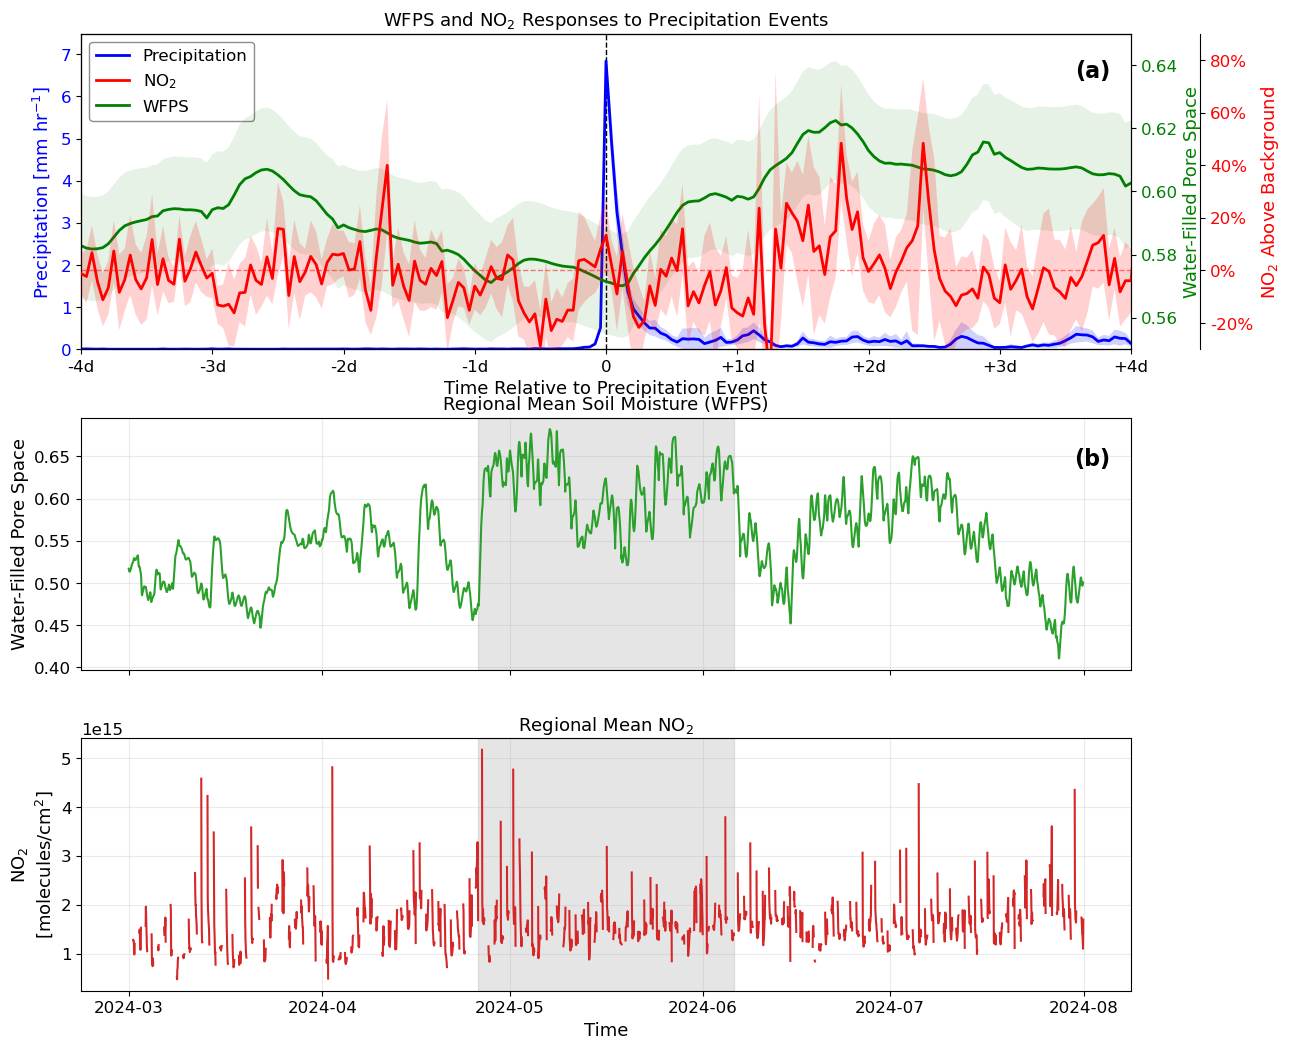

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import matplotlib.gridspec as gridspec

# -----------------------------
# Consistent figure style
# -----------------------------
plt.rcParams.update(plt.rcParamsDefault)

FONT = 13
TITLE_FONT = 13
LABEL_FONT = 13
TICK_FONT = 12
LEGEND_FONT = 12
PANEL_FONT = 16

plt.rcParams['font.size'] = FONT
plt.rcParams['axes.labelsize'] = LABEL_FONT
plt.rcParams['axes.titlesize'] = TITLE_FONT
plt.rcParams['xtick.labelsize'] = TICK_FONT
plt.rcParams['ytick.labelsize'] = TICK_FONT
plt.rcParams['legend.fontsize'] = LEGEND_FONT

# -----------------------------
# Regional mean data
# -----------------------------
df_plot = df.copy()
df_plot["datetime"] = pd.to_datetime(df_plot["datetime"])

regional = (
    df_plot.groupby("datetime")
    .agg(
        WFPS=("WFPS_c", "mean"),
        NO2=("no2_mean", "mean"),
        precip=("h_precip_mm", "mean")
    )
    .reset_index()
)

start_date = pd.to_datetime("2024-04-26")
end_date = pd.to_datetime("2024-06-06")

# -----------------------------
# Combined figure layout
# -----------------------------
fig = plt.figure(figsize=(14, 11))

gs = gridspec.GridSpec(
    3, 1,
    height_ratios=[1.25, 1, 1],
    hspace=0.25
)


# ============================================================
# PANEL A: Event-centered composite
# ============================================================
ax_precip = fig.add_subplot(gs[0])

# Precipitation axis
p_line, = ax_precip.plot(
    x,
    comp['h_precip_mm_mean_s'],
    lw=2.0,
    color='blue',
    label='Precipitation',
    zorder=5
)

ax_precip.fill_between(
    x,
    comp['h_precip_mm_lo_s'],
    comp['h_precip_mm_hi_s'],
    color='blue',
    alpha=0.18,
    edgecolor='none',
    zorder=4
)

ax_precip.set_ylabel('Precipitation [mm hr$^{-1}$]', color='blue')
ax_precip.tick_params(axis='y', labelcolor='blue', labelsize=TICK_FONT)
ax_precip.set_ylim(bottom=0)

# WFPS axis
ax_wfps = ax_precip.twinx()

w_line, = ax_wfps.plot(
    x,
    comp['WFPS_c_mean_s'],
    lw=2.0,
    color='green',
    label='WFPS',
    zorder=2
)

ax_wfps.fill_between(
    x,
    comp['WFPS_c_lo_s'],
    comp['WFPS_c_hi_s'],
    color='green',
    alpha=0.10,
    edgecolor='none',
    zorder=1
)

ax_wfps.set_ylabel('Water-Filled Pore Space', color='green')
ax_wfps.tick_params(axis='y', labelcolor='green', labelsize=TICK_FONT)
ax_wfps.set_ylim(0.55, 0.65)

# NO2 axis, offset less far right than before
ax_no2 = ax_precip.twinx()
ax_no2.spines['right'].set_position(('outward', 50))

n_line, = ax_no2.plot(
    x,
    comp['no2_norm_mean_s'],
    lw=2.0,
    color='red',
    label='NO$_2$',
    zorder=8
)

ax_no2.fill_between(
    x,
    comp['no2_norm_lo_s'],
    comp['no2_norm_hi_s'],
    color='red',
    alpha=0.18,
    edgecolor='none',
    zorder=7
)

ax_no2.axhline(
    1.0,
    ls='--',
    color='red',
    lw=1,
    alpha=0.5,
    zorder=6
)

ax_no2.set_ylabel('NO$_2$ Above Background', color='red')
ax_no2.tick_params(axis='y', labelcolor='red', labelsize=TICK_FONT)

ax_no2.yaxis.set_major_formatter(
    FuncFormatter(lambda v, pos: f'{(v - 1) * 100:.0f}%')
)

ax_no2.set_ylim(0.7, 1.9)

# Event marker and x-axis
ax_precip.axvline(0, ls='--', color='k', lw=1)

ax_precip.set_xlabel('Time Relative to Precipitation Event')
ax_precip.set_xlim(-96, 96)
ax_precip.set_xticks(range(-96, 97, 24))
ax_precip.set_xticklabels(
    [f'{h // 24:+d}d' if h != 0 else '0' for h in range(-96, 97, 24)]
)

ax_precip.set_title('WFPS and NO$_2$ Responses to Precipitation Events')

# Legend
ax_precip.legend(
    handles=[p_line, n_line, w_line],
    labels=['Precipitation', 'NO$_2$', 'WFPS'],
    loc='upper left',
    frameon=True,
    facecolor='white',
    edgecolor='gray',
    framealpha=0.9
)

# Panel label
ax_precip.text(
    0.98, 0.92,
    "(a)",
    transform=ax_precip.transAxes,
    ha="right",
    va="top",
    fontsize=PANEL_FONT,
    fontweight="bold"
)

# ============================================================
# PANEL B: Regional mean time series
# ============================================================
ax_reg_wfps = fig.add_subplot(gs[1])
ax_reg_no2 = fig.add_subplot(gs[2], sharex=ax_reg_wfps)

# Regional WFPS
ax_reg_wfps.plot(
    regional["datetime"],
    regional["WFPS"],
    color="tab:green",
    lw=1.5
)

ax_reg_wfps.set_ylabel("Water-Filled Pore Space")
ax_reg_wfps.set_title("Regional Mean Soil Moisture (WFPS)")
ax_reg_wfps.grid(alpha=0.25)

# Regional NO2
ax_reg_no2.plot(
    regional["datetime"],
    regional["NO2"],
    color="tab:red",
    lw=1.5
)

ax_reg_no2.set_ylabel("NO$_2$\n[molecules/cm$^2$]")
ax_reg_no2.set_title("Regional Mean NO$_2$")
ax_reg_no2.set_xlabel("Time")
ax_reg_no2.grid(alpha=0.25)

# Highlight period
for ax in [ax_reg_wfps, ax_reg_no2]:
    ax.axvspan(
        start_date,
        end_date,
        color="gray",
        alpha=0.2,
        zorder=0
    )
    ax.tick_params(axis='both', labelsize=TICK_FONT)

# Panel label
ax_reg_wfps.text(
    0.98, 0.88,
    "(b)",
    transform=ax_reg_wfps.transAxes,
    ha="right",
    va="top",
    fontsize=PANEL_FONT,
    fontweight="bold"
)

plt.setp(ax_reg_wfps.get_xticklabels(), visible=False)


fig.subplots_adjust(
    left=0.09,
    right=0.84,
    top=0.95,
    bottom=0.08,
    hspace=0.30
)

plt.savefig(
    '/global/home/users/toireasamarie/Paper_Workflow/Paper Figures/combined_precip_regional_figure.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()